Using acoustical_properties_from_Imaging.ipynb (/tpas git) file but looping over different a values to get pseudo-CT parameters.
There was a mistake that was:

Fix 1 — CT block:
Replace:
HU_CT[:CT_raw.shape[2],:,:] = CT_raw * seg[:segmentation.shape[0],:,:]
With:
HU_CT[:CT_raw.shape[0],:,:] = CT_raw * seg[:CT_raw.shape[0],:,:]

Fix 2 — MRI block inside the a loop:
Replace:
HU[:mr_raw.shape[2],:,:] = (1 - mr_raw) * a * seg_a[:segmentation.shape[0],:,:]
Witrh:
HU[:mr_raw.shape[0],:,:] = (1 - mr_raw) * a * seg_a[:mr_raw.shape[0],:,:]

Author: Thomas Kirchner

Additional contributor: Maylis Müller

In [1]:
import numpy as np
import nrrd
import matplotlib.pyplot as plt 
import matplotlib.gridspec as gridspec
from skimage.filters import threshold_sauvola
from scipy import ndimage
import scipy.io as sio

def plot_three_medial_planes(look_at):
    gs = gridspec.GridSpec(1,3)
    plt.figure(figsize=(6, 3))
    ax = plt.subplot(gs[0])
    plt.imshow(look_at[int(len(look_at[:,0,0])/2),:,:], vmin=np.min(look_at), vmax=np.max(look_at))

    ax = plt.subplot(gs[1])
    plt.imshow(look_at[:,int(len(look_at[0,:,0])/2),:], vmin=np.min(look_at), vmax=np.max(look_at))

    ax = plt.subplot(gs[2])
    plt.imshow(look_at[:,:,int(len(look_at[0,0,:])/2)], vmin=np.min(look_at), vmax=np.max(look_at))
    plt.colorbar()

PATH_muCT = "../../tu_muellerm_cloud/skulls_FUN/muCT.nrrd"
PATH_MR04 = "../../tu_muellerm_cloud/skulls_FUN/MR_HR.nrrd"
PATH_CT04 = "../../tu_muellerm_cloud/skulls_FUN/CT_0.67_ROI.nrrd"

mr_raw, mr_options = nrrd.read(PATH_MR04)
CT_raw, CT_options = nrrd.read(PATH_CT04)
muCT_raw, muCT_options = nrrd.read(PATH_muCT)
CT_raw = np.swapaxes(CT_raw[10:448+10,10:448+10,::-1], 0, 2)
mr_raw = np.swapaxes(mr_raw[10:448+10,10:448+10,::-1], 0, 2)
muCT_raw = np.swapaxes(muCT_raw[10:448+10,10:448+10,::-1], 0, 2)

segmentation, seg_options = nrrd.read("../../tu_muellerm_cloud/skulls_FUN/bone_segmentation_closed_erode2_MRT.nrrd")
segmentation = segmentation/np.max(segmentation)
segmentation = np.swapaxes(segmentation[10:448+10,10:448+10,::-1], 0, 2)
# bone_mask_mCT, bone_mask_options = nrrd.read("skulls/bone_mask_mCT.nrrd")
# bone_mask_mCT = bone_mask_mCT/np.max(bone_mask_mCT)
# bone_mask_mCT = np.swapaxes(bone_mask_mCT[10:448+10,10:448+10,::-1], 0, 2)

1.6675496


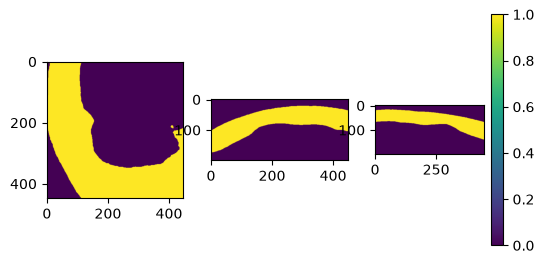

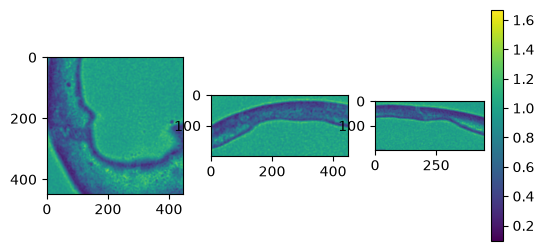

In [2]:
print(np.max(mr_raw))  
plot_three_medial_planes(segmentation)
plot_three_medial_planes(mr_raw)

In [3]:
print(np.shape(mr_raw))

(200, 448, 448)


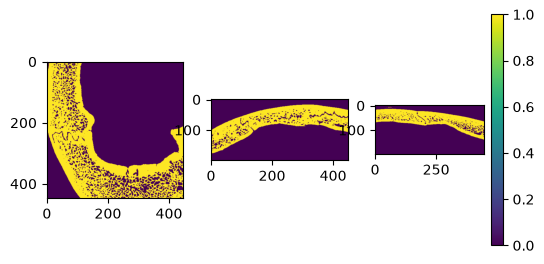

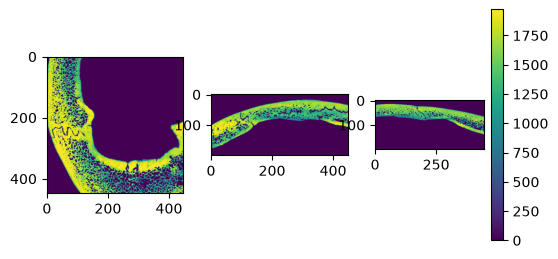

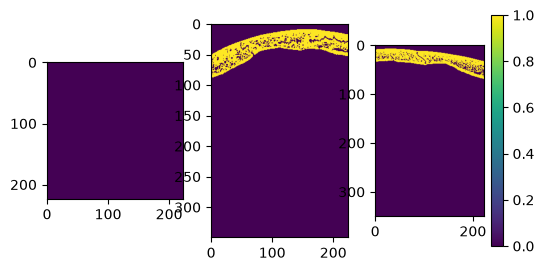

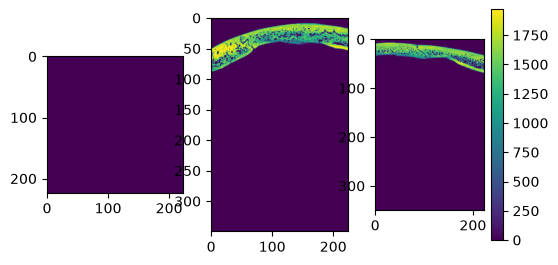

In [4]:
# ---- a-independent muCT processing (only needs to run once) ----
bone_fix = muCT_raw > 0
window_size = 15
bone_sau = muCT_raw > threshold_sauvola(muCT_raw, window_size=window_size)
bone_both = np.logical_and(bone_sau, bone_fix)
HU_muCT = muCT_raw.copy()
HU_muCT[bone_both==0] = 0
plot_three_medial_planes(bone_both)
plot_three_medial_planes(HU_muCT)

HU_ds = ndimage.zoom(HU_muCT, 0.5, order=1)
bone_fix = HU_ds > 100
window_size = 7
bone_sau = HU_ds > threshold_sauvola(HU_ds, window_size=window_size)
bone_both_ds = np.logical_and(bone_sau, bone_fix)

HU_ds_pad = np.zeros([350, 224, 224])
HU_ds_pad[:100,:,:] = HU_ds
bone_both_ds_pad = np.zeros([350, 224, 224])
bone_both_ds_pad[:100,:,:] = bone_both_ds
plot_three_medial_planes(bone_both_ds_pad)
plot_three_medial_planes(HU_ds_pad)

# sio.savemat(PATH_muCT+"_0.25mm_params.mat", 
#             {'seg':np.swapaxes(np.swapaxes(bone_both_ds_pad, 0, 2),0,1),
#              'HU':np.swapaxes(np.swapaxes(HU_ds_pad, 0, 2),0,1)})


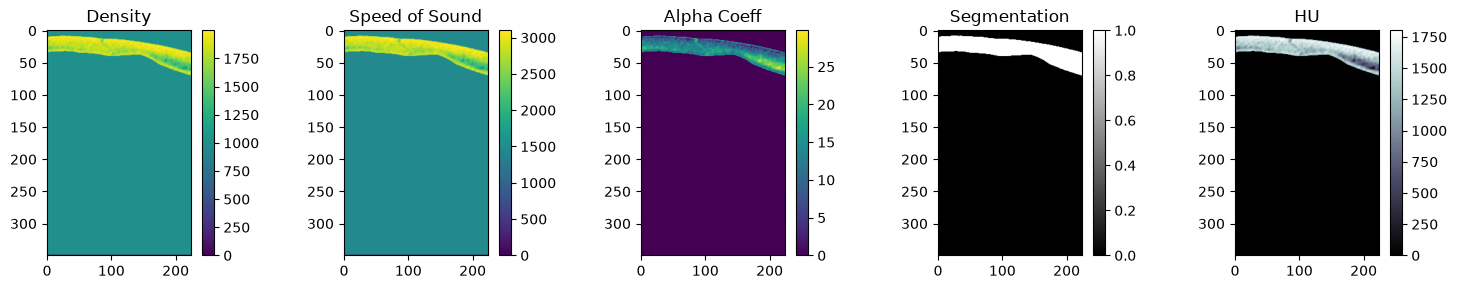

In [5]:
# ---- a-independent CT processing (only needs to run once) ----
HU_CT = np.zeros([700, 448, 448])
seg = np.zeros([700, 448, 448])
seg[:segmentation.shape[0],:,:] = segmentation
HU_CT[:CT_raw.shape[0],:,:] = CT_raw * seg[:CT_raw.shape[0],:,:]
HU_CT[HU_CT<0] = 0

HU_max = np.percentile(HU_CT, 99.9)
density_water = 1000  # [kg m^-3]
density_bone = 2000   # [kg m^-3]
speed_of_sound_water = 1480  # [m s^-1]
speed_of_sound_bone = 3100   # [m s^-1]
beta = 0.5
abs_min = 2   # [db/cm] (water)
abs_max = 30  # [db/cm] (twice average)

porosity = 1 - HU_CT/HU_max
porosity[porosity<1e-6] = 1e-6
density = (porosity * density_water + (1 - porosity) * density_bone)
speed_of_sound = (porosity * speed_of_sound_water + (1 - porosity) * speed_of_sound_bone)
alpha_coeff = (abs_min + (abs_max - abs_min) * (porosity**beta)) * seg

density_ds = ndimage.zoom(density, 0.5, order=1)
speed_of_sound_ds = ndimage.zoom(speed_of_sound, 0.5, order=1)
alpha_coeff_ds = ndimage.zoom(alpha_coeff, 0.5, order=1)
seg_ds = ndimage.zoom(seg, 0.5, order=1)
HU_CT_ds = ndimage.zoom(HU_CT, 0.5, order=1)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
center_z = HU_CT_ds.shape[2] // 2
axes[0].imshow(density_ds[:, :, center_z], cmap='viridis'); axes[0].set_title('Density')
plt.colorbar(axes[0].images[0], ax=axes[0])
axes[1].imshow(speed_of_sound_ds[:, :, center_z], cmap='viridis'); axes[1].set_title('Speed of Sound')
plt.colorbar(axes[1].images[0], ax=axes[1])
axes[2].imshow(alpha_coeff_ds[:, :, center_z], cmap='viridis'); axes[2].set_title('Alpha Coeff')
plt.colorbar(axes[2].images[0], ax=axes[2])
axes[3].imshow(seg_ds[:, :, center_z], cmap='gray'); axes[3].set_title('Segmentation')
plt.colorbar(axes[3].images[0], ax=axes[3])
axes[4].imshow(HU_CT_ds[:, :, center_z], cmap='bone'); axes[4].set_title('HU')
plt.colorbar(axes[4].images[0], ax=axes[4])
plt.tight_layout()
plt.show()

# downsampled segmentation reused inside the a-loop (a-independent)
segmentation_minres = ndimage.zoom(segmentation, 0.13, order=0)
muCT_raw_minres = ndimage.zoom(muCT_raw, 0.13, order=1)
CT_raw_minres = ndimage.zoom(CT_raw, 0.13, order=1)

# sio.savemat(PATH_CT04+"_0.25mm_params.mat", 
#             {'density':np.swapaxes(np.swapaxes(density_ds, 0, 2),0,1), 
#              'speed_of_sound':np.swapaxes(np.swapaxes(speed_of_sound_ds, 0, 2),0,1),
#              'alpha_coeff':np.swapaxes(np.swapaxes(alpha_coeff_ds, 0, 2),0,1),
#              'seg':np.swapaxes(np.swapaxes(seg_ds, 0, 2),0,1),
#              'HU':np.swapaxes(np.swapaxes(HU_ds, 0, 2),0,1)})

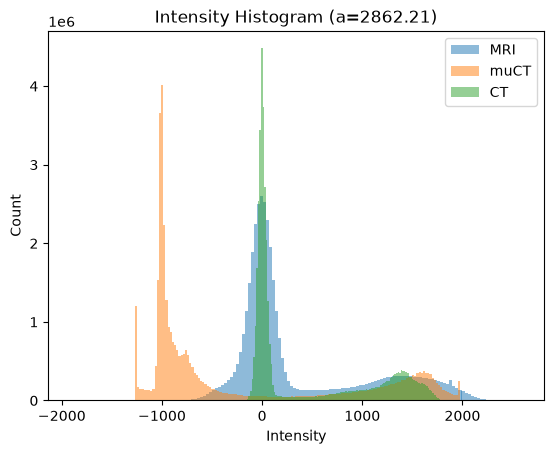

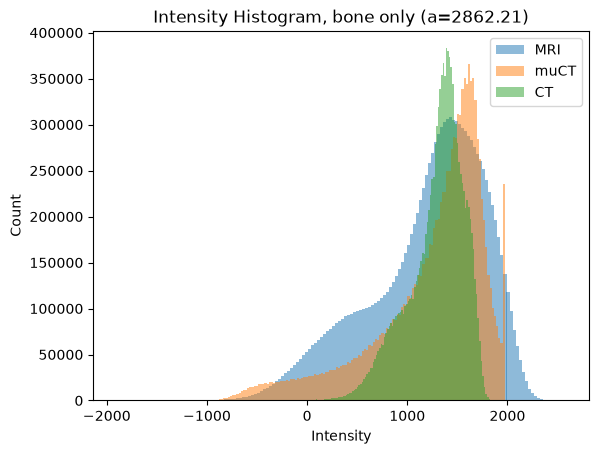

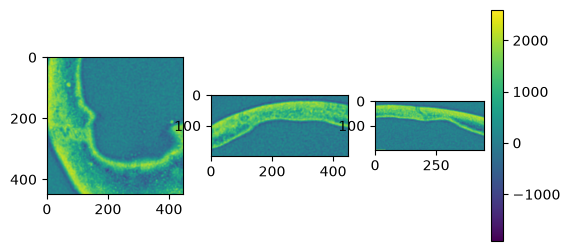

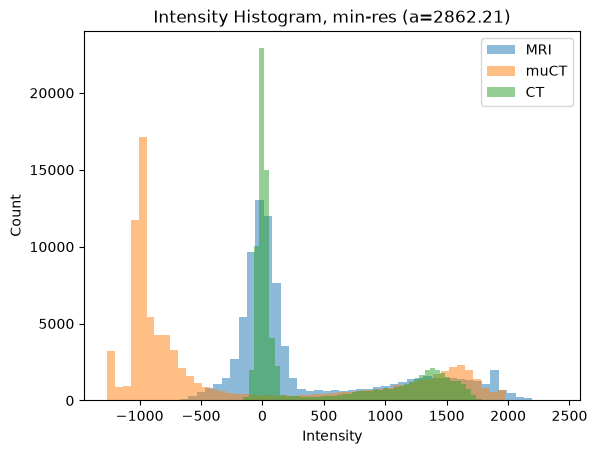

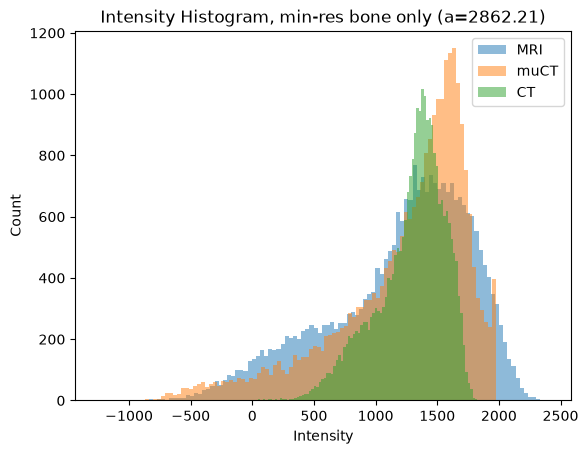

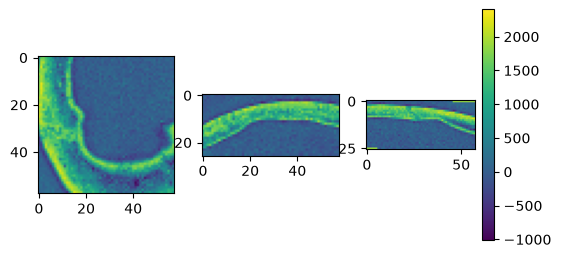

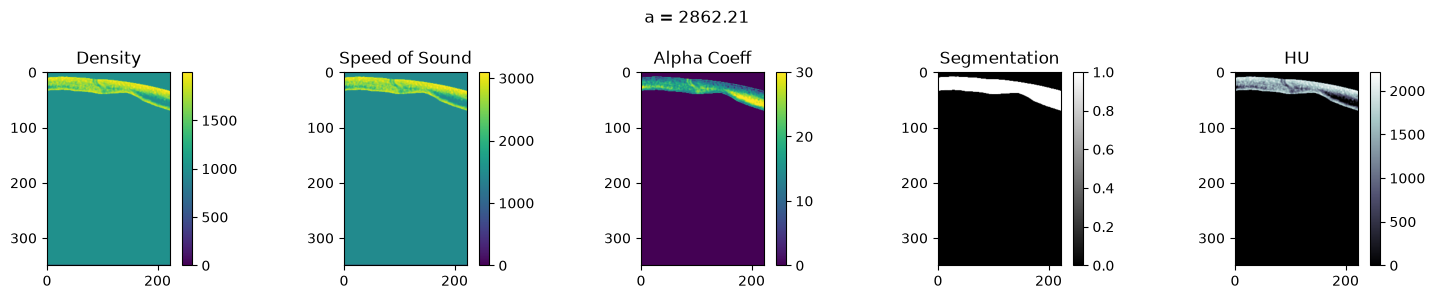

Saved ../../tu_muellerm_cloud/skulls_FUN/MR_HR.nrrd_a2862_0.25mm_params.mat


In [ ]:
a = 2862.210
b = a

# --- full-res MRI histograms ---
plt.figure()
plt.hist((b-a*mr_raw).ravel(), bins=150, alpha=0.5, label="MRI")
plt.hist((muCT_raw).ravel(), bins=150, alpha=0.5, label="muCT")
plt.hist((CT_raw).ravel(), bins=150, alpha=0.5, label="CT")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.title(f"Intensity Histogram (a={a})")
plt.legend()
plt.show()

plt.figure()
plt.hist((b-a*mr_raw[segmentation==1]).ravel(), bins=150, alpha=0.5, label="MRI")
plt.hist((muCT_raw[segmentation==1]).ravel(), bins=150, alpha=0.5, label="muCT")
plt.hist((CT_raw[segmentation==1]).ravel(), bins=150, alpha=0.5, label="CT")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.title(f"Intensity Histogram, bone only (a={a})")
plt.legend()
plt.show()

plot_three_medial_planes(b-a*mr_raw)

# --- min-res MRI histograms (uses precomputed minres volumes) ---
mr_raw_minres = ndimage.zoom(mr_raw, 0.13, order=1)

plt.figure()
plt.hist((b-a*mr_raw_minres).ravel(), bins=50, alpha=0.5, label="MRI")
plt.hist((muCT_raw_minres).ravel(), bins=50, alpha=0.5, label="muCT")
plt.hist((CT_raw_minres).ravel(), bins=50, alpha=0.5, label="CT")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.title(f"Intensity Histogram, min-res (a={a})")
plt.legend()
plt.show()

plt.figure()
plt.hist((b-a*mr_raw_minres[segmentation_minres==1]).ravel(), bins=100, alpha=0.5, label="MRI")
plt.hist((muCT_raw_minres[segmentation_minres==1]).ravel(), bins=100, alpha=0.5, label="muCT")
plt.hist((CT_raw_minres[segmentation_minres==1]).ravel(), bins=100, alpha=0.5, label="CT")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.title(f"Intensity Histogram, min-res bone only (a={a})")
plt.legend()
plt.show()

plot_three_medial_planes(a-a*mr_raw_minres)

# --- MRI -> density/speed_of_sound/alpha_coeff (a-dependent HU) ---
HU = np.zeros([700, 448, 448])
seg_a = np.zeros([700, 448, 448])
seg_a[:segmentation.shape[0],:,:] = segmentation
HU[:mr_raw.shape[0],:,:] = (b - mr_raw * a) * seg_a[:mr_raw.shape[0],:,:]
HU[HU<0] = 0

HU_max_a = np.percentile(HU, 99.9)
porosity = 1 - HU/HU_max_a
porosity[porosity<1e-6] = 1e-6
density = (porosity * density_water + (1 - porosity) * density_bone)
speed_of_sound = (porosity * speed_of_sound_water + (1 - porosity) * speed_of_sound_bone)
alpha_coeff = (abs_min + (abs_max - abs_min) * (porosity**beta)) * seg_a

density_ds = ndimage.zoom(density, 0.5, order=1)
speed_of_sound_ds = ndimage.zoom(speed_of_sound, 0.5, order=1)
alpha_coeff_ds = ndimage.zoom(alpha_coeff, 0.5, order=1)
seg_ds = ndimage.zoom(seg_a, 0.5, order=1)
HU_ds = ndimage.zoom(HU, 0.5, order=1)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
center_z = HU_ds.shape[2] // 2
axes[0].imshow(density_ds[:, :, center_z], cmap='viridis'); axes[0].set_title('Density')
plt.colorbar(axes[0].images[0], ax=axes[0])
axes[1].imshow(speed_of_sound_ds[:, :, center_z], cmap='viridis'); axes[1].set_title('Speed of Sound')
plt.colorbar(axes[1].images[0], ax=axes[1])
axes[2].imshow(alpha_coeff_ds[:, :, center_z], cmap='viridis'); axes[2].set_title('Alpha Coeff')
plt.colorbar(axes[2].images[0], ax=axes[2])
axes[3].imshow(seg_ds[:, :, center_z], cmap='gray'); axes[3].set_title('Segmentation')
plt.colorbar(axes[3].images[0], ax=axes[3])
axes[4].imshow(HU_ds[:, :, center_z], cmap='bone'); axes[4].set_title('HU')
plt.colorbar(axes[4].images[0], ax=axes[4])
plt.suptitle(f"a = {a}")
plt.tight_layout()
plt.show()

out_path = f"{PATH_MR04}_a{round(a)}_0.25mm_params.mat"
sio.savemat(out_path,
            {'density':np.swapaxes(np.swapaxes(density_ds, 0, 2),0,1),
                'speed_of_sound':np.swapaxes(np.swapaxes(speed_of_sound_ds, 0, 2),0,1),
                'alpha_coeff':np.swapaxes(np.swapaxes(alpha_coeff_ds, 0, 2),0,1),
                'seg':np.swapaxes(np.swapaxes(seg_ds, 0, 2),0,1),
                'HU':np.swapaxes(np.swapaxes(HU_ds, 0, 2),0,1)})
print(f"Saved {out_path}")